# 02 — Forecasting load and PV

The hours of day D+1 are forecast at midnight between D and D+1, using only measurements up to the end of day D. The notebook reads the results of `python -m microgrid.forecast`.

Three forecasts are compared:

- **naive**: same hour 7 days earlier for load, same hour of the previous day for PV;
- **LightGBM static**: trained once, before the period to forecast begins;
- **LightGBM refit every 7 days**: same hyperparameters, but refitted every week on all the measurements available up to then. This is the forecast the system will use.

The weather of day D+1 is the observed one, used as if it were a forecast: an optimistic simplification.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from microgrid.config import load_config, resolve_path
from microgrid.dataset import local_index
from microgrid.forecast import METRICS_FILE, NAIVE, PARAMS_FILE, STATIC, load_forecasts, refit_label
from microgrid.plotting import COLORS, TEXT_SECONDARY, apply_style

apply_style()
config = load_config()
results_dir = resolve_path(config["paths"]["results"])
forecasts = load_forecasts(config)
forecasts.index = local_index(forecasts.index, config)
test = forecasts[forecasts["split"] == "test"]
refit = refit_label(config)
print(f"Validation: {(forecasts['split'] == 'validation').sum()} hours   test: {len(test)} hours")

Validation: 2952 hours   test: 3001 hours


## 1. Hyperparameters

Chosen with a 4-fold expanding-window cross-validation on the training data only: each fold trains on one period and validates on the next. Every combination of the grid in `config/default.yaml` is tried.

In [2]:
chosen = json.loads((results_dir / PARAMS_FILE).read_text())
rows = []
for target, result in chosen.items():
    trials = pd.DataFrame([{**trial["params"], "cv_mae": trial["cv_mae"]} for trial in result["trials"]])
    rows.append({"target": target, **result["params"], "trees": result["rounds"],
                 "CV MAE (kW)": round(result["cv_mae"], 3),
                 "worst MAE in the grid (kW)": round(trials["cv_mae"].max(), 3),
                 "combinations tried": len(trials)})
pd.DataFrame(rows).set_index("target")

,num_leaves,min_child_samples,reg_lambda,trees,CV MAE (kW),worst MAE in the grid (kW),combinations tried
target,,,,,,,
load_kw,7,50,10.0,255,3.275,3.427,18
pv_kw,7,100,10.0,187,5.198,5.411,18


**What we see**

- For both targets the smallest trees in the grid win (7 leaves), with the strongest regularisation: with little more than a year and a half of data, simple models generalise better.
- The difference between the best and the worst combination is small (about 4%): the result depends little on the hyperparameters.

## 2. Metrics

MAE and RMSE in kW; the normalised MAE is the MAE divided by the mean of the actual values. The three forecasts are evaluated on the same hours.

In [3]:
table = pd.read_csv(results_dir / METRICS_FILE)
naive_mae = table[table["model"] == NAIVE].set_index(["target", "split"])["mae"]
table["MAE vs naive"] = [
    f"{(row.mae / naive_mae[(row.target, row.split)] - 1):+.0%}" if row.model != NAIVE else ""
    for row in table.itertuples()
]
table = table.rename(columns={"model": "forecast", "mae": "MAE", "rmse": "RMSE", "nmae": "normalised MAE"})
table.set_index(["target", "split", "forecast"]).round(3)

hours    MAE    RMSE  \
target split      forecast                                            
load   validation naive                         2952  3.160   5.437   
                  LightGBM static               2952  2.400   3.853   
                  LightGBM refit every 7 days   2952  2.380   3.849   
       test       naive                         3001  3.343   5.633   
                  LightGBM static               3001  3.839   5.719   
                  LightGBM refit every 7 days   3001  3.460   5.054   
pv     validation naive                         2952  7.503  15.823   
                  LightGBM static               2952  4.597   9.235   
                  LightGBM refit every 7 days   2952  4.553   9.142   
       test       naive                         3001  5.788  14.093   
                  LightGBM static               3001  3.567   8.245   
                  LightGBM refit every 7 days   3001  3.528   8.161   

                                               normalised MAE MAE vs naive  
target split      forecast                                                  
load   validation naive                                 0.606               
                  LightGBM static                       0.461         -24%  
                  LightGBM refit every 7 days           0.457         -25%  
       test       naive                                 0.275               
                  LightGBM static                       0.316         +15%  
                  LightGBM refit every 7 days           0.285          +4%  
pv     validation naive                                 0.440               
                  LightGBM static                       0.269         -39%  
                  LightGBM refit every 7 days           0.267         -39%  
       test       naive                                 0.804               
                  LightGBM static                       0.496         -38%  
                  LightGBM refit every 7 days           0.490         -39%

**What we see**

- **PV.** The model cuts MAE by 39% compared with the naive forecast, both in validation and on the test set. Refitting changes little.
- **Load, validation (summer).** The model cuts MAE by 25%.
- **Load, test (autumn–winter).** The model does **not** beat the naive forecast on MAE: +4% refitted, +15% static. It is better only on RMSE (5.05 against 5.63 kW), i.e. it makes fewer large errors.
- In winter the normalised MAE of PV is high (0.49) because mean output is low; in kW the error is smaller than in summer.

## 3. Forecast and actual over one week of the test set

Load: MAE over the week 2.54 kW
PV: MAE over the week 4.05 kW


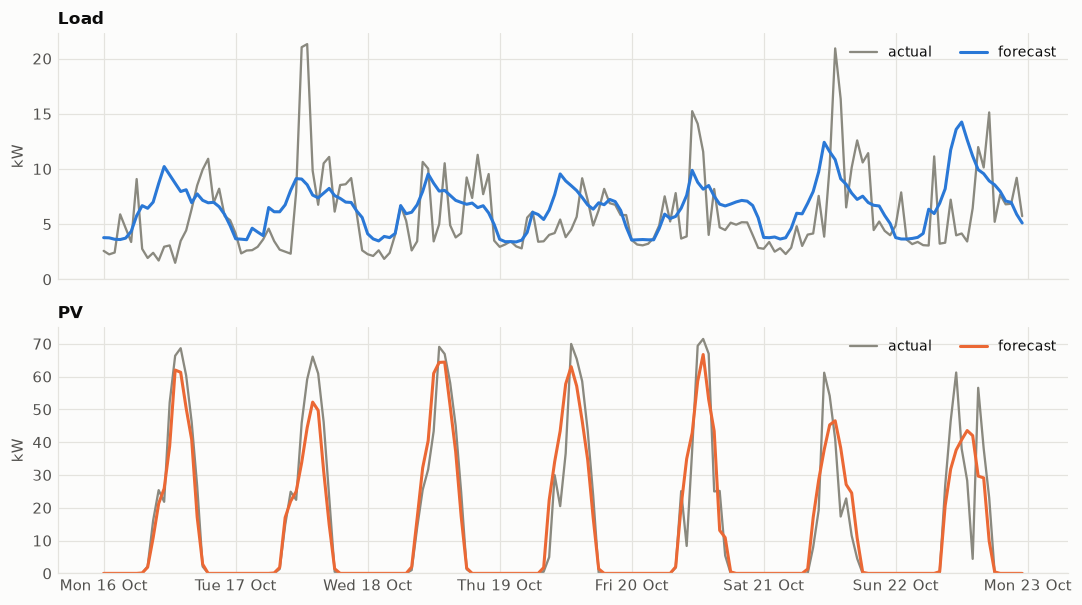

In [4]:
week = test.loc["2017-10-16":"2017-10-22"]
panels = [("load_kw", "load_forecast", "load", "Load"), ("pv_kw", "pv_forecast", "pv", "PV")]
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
for ax, (actual, predicted, color, title) in zip(axes, panels):
    ax.plot(week.index, week[actual], color=COLORS["muted"], linewidth=1.5, label="actual")
    ax.plot(week.index, week[predicted], color=COLORS[color], label="forecast")
    ax.set_ylim(0, None)
    ax.set_ylabel("kW")
    ax.set_title(title)
    ax.legend(loc="upper right", ncols=2, fontsize=9)
    error = (week[predicted] - week[actual]).abs().mean()
    print(f"{title}: MAE over the week {error:.2f} kW")
axes[-1].xaxis.set_major_locator(mdates.DayLocator(tz=week.index.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=week.index.tz))
fig.tight_layout()
plt.show()

**What we see**

- The PV forecast follows the shape of the day well; it goes wrong on days of changeable cloud (Saturday 21 and Sunday 22), where hourly weather does not capture passing clouds.
- The load forecast is a smoothed version of the actual one: the level and the shape of the day are right, the one- or two-hour peaks are not. With only two households those peaks depend on single appliances and cannot be predicted a day ahead.

## 4. Error by hour of day

MAE on the test set by local hour, naive forecast and refitted model.

Load
utc_timestamp   0    1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23
naive          2.8  2.1  1.5  1.6  1.3  1.6  2.1  3.2  4.1  4.7  4.9  4.6  5.3  5.8  4.0  3.6  4.0  4.0  2.7  3.3  3.4  3.8  2.7  2.9
LightGBM       2.1  1.9  1.4  1.8  1.3  2.1  1.9  3.0  4.9  6.1  7.2  4.7  6.2  6.0  5.0  4.1  4.4  3.7  2.7  2.5  3.1  2.9  2.0  2.2
PV
utc_timestamp   0    1    2    3    4    5    6    7    8     9     10    11    12    13    14    15   16   17   18   19   20   21   22   23
naive          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.9  10.2  15.1  22.7  24.6  22.4  18.9  14.9  6.1  2.0  0.3  0.0  0.0  0.0  0.0  0.0
LightGBM       0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.5   6.7   9.5  13.3  15.0  12.6  11.3   8.6  4.3  1.7  0.2  0.0  0.0  0.0  0.0  0.0


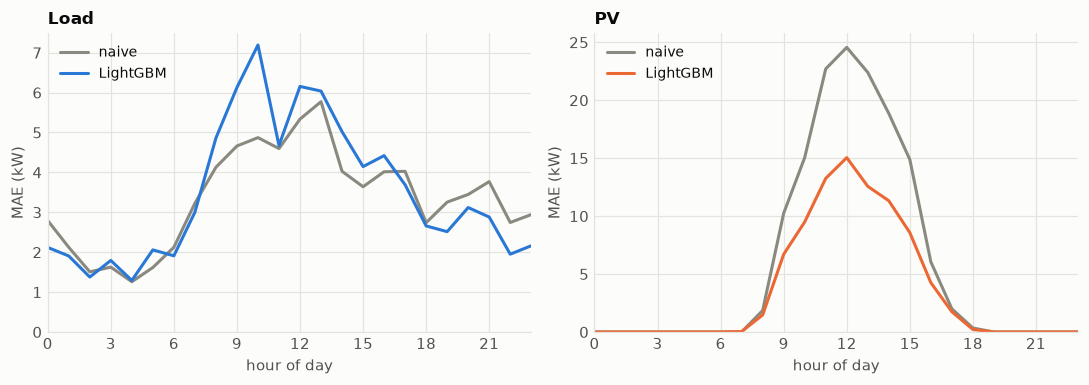

In [5]:
panels = [("load_kw", "load", "Load"), ("pv_kw", "pv", "PV")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (actual, name, title) in zip(axes, panels):
    by_hour = pd.DataFrame({
        "naive": (test[f"{name}_naive"] - test[actual]).abs().groupby(test.index.hour).mean(),
        "LightGBM": (test[f"{name}_forecast"] - test[actual]).abs().groupby(test.index.hour).mean(),
    })
    ax.plot(by_hour.index, by_hour["naive"], color=COLORS["muted"], label="naive")
    ax.plot(by_hour.index, by_hour["LightGBM"], color=COLORS[name], label="LightGBM")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_ylim(0, None)
    ax.set_xlabel("hour of day")
    ax.set_ylabel("MAE (kW)")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=9)
    print(title)
    print(by_hour.round(1).T.to_string())
fig.tight_layout()
plt.show()

**What we see**

- **PV.** The model nearly halves the error of the naive forecast in the middle of the day (15 kW against 25 kW at noon).
- **Load.** The model is better at night and in the evening, worse between 8 and 14. The error peaks at 10 (7.2 kW against 4.9 kW).

## 5. Load error month by month

The load result changes a lot within the test set: it is worth looking at it by month.

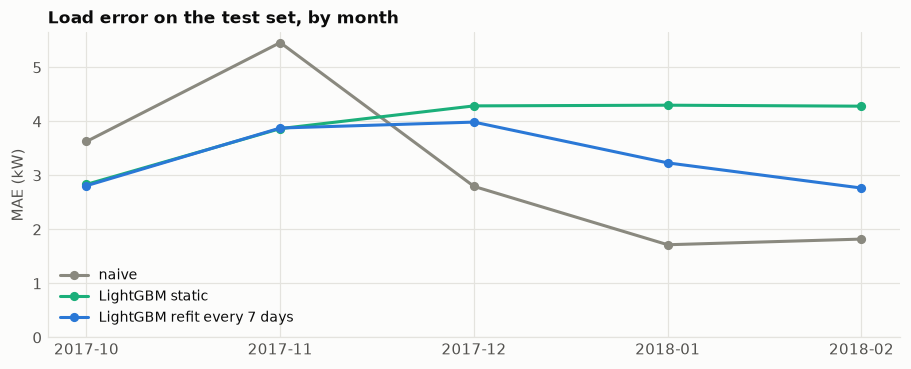

,naive,LightGBM static,LightGBM refit every 7 days,mean load
utc_timestamp,,,,
2017-10,3.63,2.83,2.81,6.85
2017-11,5.46,3.87,3.88,12.90
2017-12,2.80,4.29,3.99,14.55
2018-01,1.72,4.30,3.23,13.88
2018-02,1.82,4.28,2.77,14.78


In [6]:
month = test.index.tz_localize(None).to_period("M")
columns = {NAIVE: "load_naive", STATIC: "load_forecast_static", refit: "load_forecast"}
monthly = pd.DataFrame({name: (test[column] - test["load_kw"]).abs().groupby(month).mean()
                        for name, column in columns.items()})
monthly["mean load"] = test["load_kw"].groupby(month).mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
positions = range(len(monthly))
styles = [(NAIVE, COLORS["muted"]), (STATIC, COLORS["alt"]), (refit, COLORS["load"])]
for name, color in styles:
    ax.plot(positions, monthly[name], color=color, marker="o", markersize=5, label=name)
ax.set_xticks(positions, [str(period) for period in monthly.index])
ax.set_ylim(0, None)
ax.set_ylabel("MAE (kW)")
ax.set_title("Load error on the test set, by month")
ax.legend(loc="lower left", fontsize=9)
plt.show()

monthly.round(2)

**What we see**

- In October and November the model beats the naive forecast by more than 20%.
- From December the ranking flips. In winter 2017–18 the load has a very regular weekly pattern, with a peak between 8 and 10 that was not there in the previous winters: repeating the week before works extremely well (MAE 1.7 kW in January), while the model learned from two years in which that habit did not exist.
- Weekly refitting recovers part of the gap (from 4.3 to 2.8 kW in February), but not enough to catch the naive forecast.
- The static model does not adapt at all: its error stays at 4.3 kW for three months.

## Conclusions

- The system will use the model **refitted every 7 days**, which is also the best in validation for both targets.
- **Caveat.** Refitting was introduced after seeing that the static model got worse on the test set. It uses no future data, it is normal operating practice and the hyperparameters were not changed; it is still a choice made knowing the test result.
- On PV the forecast is clearly better than the naive one.
- On load, in the test set, it is on a par with the naive one: better on large errors, worse on the mean error. The cause is a change of habits in one of the two households, not a flaw in the data.
- The weather used is the observed one: with real weather forecasts the PV error would be higher.
- The simulation will tell how much of this error turns into cost: the `load_naive` column stays in the forecast file so that the two can be compared.